[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/prep/P0_radar_inventory.ipynb)

# P0 — สำรวจข้อมูลเรดาร์ UF ทั้งเดือน (inventory)

**สำหรับอาจารย์ผู้ดูแลข้อมูลเท่านั้น** ไฟล์ UF เป็นข้อมูลของกรมอุตุนิยมวิทยาที่ไม่อนุญาตให้เผยแพร่ notebook นี้อ่านจาก Google Drive ส่วนตัว และเขียนออกเฉพาะ **ตารางสรุป** (ไม่มีข้อมูลเรดาร์) ซึ่งเผยแพร่ใน repo ได้

**ทำอะไร**
1. อ่านชื่อและขนาดไฟล์ทุกไฟล์ (ไม่กี่วินาที) → เวลา UTC, จับเข้าช่อง 15 นาที, หาไฟล์เหลื่อมเวลา ไฟล์ซ้ำ ไฟล์เล็กผิดปกติ
2. เปิดไฟล์ทุกไฟล์ด้วย Py-ART อ่าน metadata แบบขนาน → พิกัดเรดาร์จริง มุมยก Nyquist ไฟล์เสีย (มี cache รันซ้ำได้)
3. สรุปรายวัน: ความครอบคลุม ช่องว่าง ช่วงต่อเนื่องสำหรับ tracking และวันที่ใช้ได้
4. แผนภาพความพร้อมของข้อมูล ซ้อนกับหน้าต่างเวลาของรายงานความเสียหาย (จากบท 01)

**Runtime ที่แนะนำ:** CPU + High-RAM ขั้นที่ 2 ใช้ทุก core ที่มี ไม่ต้องใช้ GPU

**ผลลัพธ์** (เขียนทั้งใน Drive และในโฟลเดอร์ repo ที่ clone ไว้)

| ไฟล์ | เนื้อหา |
|---|---|
| `data/inventory/radar_inventory.csv` | ช่อง 15 นาทีทั้งเดือน สถานะ ชื่อไฟล์ metadata |
| `data/inventory/daily_summary.csv` | สรุปรายวันและเกณฑ์ใช้ได้ |
| `data/inventory/segments.csv` | ช่วงต่อเนื่องที่ใช้ติดตามพายุได้ |
| `data/inventory/scan_strategies.csv` | รูปแบบการสแกนที่พบและช่วงเวลา |
| `config/radar_site.json` | พิกัดเรดาร์จริงจาก UF (ทุก notebook จะใช้ค่านี้แทนค่าประมาณ) |

In [1]:
# @title ⚙️ เชื่อม Drive, clone repo, ติดตั้ง Py-ART
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt", "arm_pyart"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import psutil
print(f"CPU {os.cpu_count()} core | RAM {psutil.virtual_memory().total / 2**30:.1f} GB | โฟลเดอร์ทำงาน {os.getcwd()}")

Mounted at /content/drive
CPU 8 core | RAM 51.0 GB | โฟลเดอร์ทำงาน /content/Teach_stormTracks_KKN_May2024_HID_doppler


In [2]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm

from utils.config import load_settings, repo_path
from utils import radar_inventory as RI, maps as M

s = load_settings()
M.setup_style()

# ---- ตั้งค่า path (แก้ได้ หรือกำหนดผ่านตัวแปรสภาพแวดล้อม) ----
RAW_ROOT = Path(os.environ.get("KKN_RAW_ROOT", s["radar_data"]["drive_raw_root"]))   # .../KKN/2405DD/*.uf.bz2
OUT_ROOT = Path(os.environ.get("KKN_OUT_ROOT", s["radar_data"]["drive_derived_root"]))
MONTH_PREFIX = "2405"
READ_METADATA = True        # False = ทำเฉพาะขั้นที่ 1 (เร็วมาก)

if not RAW_ROOT.exists():
    # ช่วยหาโฟลเดอร์ชื่อ KKN ที่มีโฟลเดอร์ย่อย 2405xx ใน My Drive (ค้นลึกไม่เกิน 7 ชั้น)
    base = Path("/content/drive/MyDrive")
    found = []
    for d in range(0, 7):
        for p in base.glob("*/" * d + "KKN"):
            if p.is_dir() and any(p.glob(MONTH_PREFIX + "*")):
                found.append(str(p))
    raise FileNotFoundError(f"ไม่พบ {RAW_ROOT}\nโฟลเดอร์ที่น่าจะใช่: {found}\n"
                            "คัดลอก path ที่ถูกต้องไปใส่ใน RAW_ROOT ด้านบน (หรือแก้ drive_raw_root ใน config/settings.yaml) แล้วรันใหม่")
INV_OUT = OUT_ROOT / "inventory"; INV_OUT.mkdir(parents=True, exist_ok=True)
INV_REPO = repo_path("data", "inventory"); INV_REPO.mkdir(parents=True, exist_ok=True)
print("UF :", RAW_ROOT, "| โฟลเดอร์รายวัน:", len(list(RAW_ROOT.glob(MONTH_PREFIX + "*"))))
print("OUT:", OUT_ROOT)

UF : /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN | โฟลเดอร์รายวัน: 31
OUT: /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1


## ขั้นที่ 1 — รายชื่อไฟล์และช่องเวลา 15 นาที

ชื่อไฟล์ `KKN240@202405050015.uf.bz2` บอก สถานี (KKN) ผลิตภัณฑ์ (240 = รัศมี 240 km) และเวลา **UTC** (ปี เดือน วัน ชั่วโมง นาที) เราจับแต่ละไฟล์เข้าช่องมาตรฐาน 15 นาที

$$t_{\text{slot}} = \operatorname{round}\!\left(\tfrac{t}{15\ \text{min}}\right)\times 15\ \text{min}, \qquad \text{offset} = t - t_{\text{slot}}$$

ไฟล์ที่ offset เกิน ±3 นาทีจะติดป้าย `offset` (ยังใช้ได้ แต่ต้องรู้ไว้เมื่อคำนวณความเร็วพายุ) ไฟล์ที่เล็กกว่า 60% ของมัธยฐานรายวันติดป้าย `small` (มักเป็นไฟล์ที่ส่งมาไม่ครบ)

In [3]:
t0 = time.time()
files = RI.list_files(RAW_ROOT, s, MONTH_PREFIX)
files = RI.assign_slots(files, s)
print(f"พบ {len(files)} ไฟล์ใน {files['folder'].nunique()} โฟลเดอร์ ({time.time() - t0:.1f} วินาที), รวม {files['size_mb'].sum() / 1024:.2f} GB")
print(files["status"].value_counts().to_string())
files[files["status"] != "ok"][["folder", "file", "size_mb", "offset_min", "status"]].head(20)

พบ 1957 ไฟล์ใน 21 โฟลเดอร์ (15.1 วินาที), รวม 7.64 GB
status
ok          1924
bad_name      33


,folder,file,size_mb,offset_min,status
1924,240503,KKN_PPI_vs_CAPPI_corr_uncorr.png,2.570582,NaN,bad_name
1925,240503,KKN_PPI_vs_CAPPI_corr_uncorr.pdf,13.152728,NaN,bad_name
1926,240503,KKN_PPI_vs_CAPPI_flareRemoved.png,2.541986,NaN,bad_name
1927,240503,KKN_PPI_vs_CAPPI_flareRemoved.pdf,13.031711,NaN,bad_name
1928,240503,KKN_velocity_dealias_sweep0_1.png,0.814728,NaN,bad_name
1929,240503,KKN_CAPPI_5panel.png,1.278706,NaN,bad_name
1930,240503,KKN_pseudoRHI_az315.png,0.273510,NaN,bad_name
1931,240503,KKN_SNK_prePyDDA_Z_V.png,2.610119,NaN,bad_name
1932,240503,KKN_SNK_clean_reflectivity_2x2.png,2.958565,NaN,bad_name
1933,240503,KKN_SNK_gridded_velocity_slice.png,0.327248,NaN,bad_name


### ตรวจชนิดการบีบอัดจริงของไฟล์

นามสกุล `.bz2` ไม่ได้รับประกันว่าเนื้อไฟล์เป็น bzip2 เราดู **magic bytes** (ไบต์แรกของไฟล์) แทน: `42 5a 68` = bzip2, `1f 8b` = gzip, `50 4b` = zip, มี `55 46` ("UF") ในไบต์ต้น ๆ = UF ที่ไม่ได้บีบอัด ฟังก์ชัน `utils/radar_io.py` เลือกวิธีแตกไฟล์ตามเนื้อจริง จึงไม่ติดปัญหา `OSError: Invalid data stream` ที่เกิดเมื่อให้ Py-ART เดาจากนามสกุล

In [4]:
from utils.radar_io import detect
sample = files[files["status"] == "ok"].groupby("folder").head(2)
kinds = []
for p_ in sample["path"]:
    with open(p_, "rb") as f:
        kinds.append(detect(f.read(16)))
print(pd.Series(kinds, name="ชนิดการบีบอัดที่พบ (ตัวอย่างวันละ 2 ไฟล์)").value_counts().to_string())

ชนิดการบีบอัดที่พบ (ตัวอย่างวันละ 2 ไฟล์)
gzip    42


## ขั้นที่ 2 — metadata จากไฟล์จริง (ขนาน + cache)

Py-ART อ่านไฟล์ `.uf.bz2` ได้โดยตรง เราอ่านทุกไฟล์ที่ผ่านขั้นที่ 1 เพื่อ (ก) หาไฟล์ที่เปิดไม่ได้ (ข) ดูว่ามุมยกและ **Nyquist velocity** เปลี่ยนระหว่างวันหรือไม่ — ใน repo ก่อนพบว่า Vny เปลี่ยนจาก 16.75 เป็น 8.38 m/s ระหว่างวัน ซึ่งกำหนดวิธี dealiasing ใน P2 (ค) อ่านพิกัดเรดาร์จริง

ถ้า Colab หลุด ให้รันเซลล์นี้ซ้ำ จะอ่านต่อเฉพาะไฟล์ที่ยังไม่ได้อ่าน (cache เก็บใน Drive)

In [5]:
use = files[files["status"].isin(["ok", "offset", "small"])]
if READ_METADATA:
    t0 = time.time()
    meta = RI.read_metadata_many(use["path"].tolist(), cache_csv=INV_OUT / "meta_cache.csv")
    dt = time.time() - t0
    print(f"ใช้เวลา {dt / 60:.1f} นาที")
    files = files.merge(meta, on="path", how="left")
    bad = files["read_ok"] == False  # noqa: E712
    files.loc[bad, "status"] = "corrupt"
    print("เปิดไม่ได้:", int(bad.sum()), "ไฟล์")
    display(files.loc[bad, ["file", "size_mb", "error"]].head(20))

ต้องอ่าน 1924 ไฟล์ (มีใน cache แล้ว 0)

## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119

## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119

## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly 

,file,size_mb,error


In [6]:
# พิกัดเรดาร์จริง (ค่ามัธยฐานจากทุกไฟล์) → config/radar_site.json
if READ_METADATA and files["read_ok"].any():
    ok = files[files["read_ok"] == True]  # noqa: E712
    site = {"name": s["radar"]["name"], "lat": round(float(ok["lat"].median()), 5),
            "lon": round(float(ok["lon"].median()), 5), "alt_m": round(float(ok["alt_m"].median()), 1),
            "lat_spread": float(ok["lat"].max() - ok["lat"].min()), "n_files": int(len(ok)),
            "source": "UF header (prep/P0)"}
    for p in (repo_path("config", "radar_site.json"), INV_OUT / "radar_site.json"):
        p.write_text(json.dumps(site, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(site, ensure_ascii=False, indent=2))
    print(f"ค่าประมาณเดิม: {s['radar']['lat']}, {s['radar']['lon']}")

{
  "name": "KKN",
  "lat": 16.4625,
  "lon": 102.78588,
  "alt_m": 217.0,
  "lat_spread": 0.0,
  "n_files": 1924,
  "source": "UF header (prep/P0)"
}
ค่าประมาณเดิม: 16.46, 102.79


In [7]:
# รูปแบบการสแกนที่พบ (มุมยก + Nyquist + ระยะ) และช่วงเวลาที่ใช้
if READ_METADATA:
    strat = RI.scan_strategies(files)
    display(strat)

,n_files,first,last,nsweeps,gate_m
strategy,,,,,
0.5;1.5;2.4;3.4 | Vny 8.38;8.38;8.38;8.38 | 240.0 km,1814,2024-05-03 03:30:00,2024-05-27 02:30:00,4.0,500.0
0.5;1.5;2.4;3.4 | Vny 16.75;16.75;16.75;16.75 | 240.0 km,110,2024-05-01 00:00:00,2024-05-03 03:15:00,4.0,500.0


## ขั้นที่ 3 — ตารางช่องเวลาทั้งเดือน สรุปรายวัน และช่วงต่อเนื่อง

**กติกาที่ใช้ตลอดชุดบทเรียน** (แก้ได้ใน `config/settings.yaml`)

- ช่องที่ใช้ได้ = `ok` หรือ `offset`
- **ช่วงต่อเนื่อง (segment)**: ภาพที่ห่างกันไม่เกิน 15 นาที การติดตามพายุทำได้ภายในช่วงเท่านั้น ช่องว่าง ≥ 30 นาทีตัดเส้นทาง (repo ก่อนพบว่าการเชื่อมข้าม 30 นาทีได้ CSI35 เพียง 0.18)
- **ความครอบคลุมช่วงพายุหลัก** = สัดส่วนช่องที่ใช้ได้ระหว่าง 05–17 UTC (12–24 น.) วันที่ ≥ 80% ถือว่า **ใช้ได้เต็มที่** วันที่ต่ำกว่ายังใช้ใน heatmap ได้ แต่ต้องถ่วงน้ำหนักด้วยเวลาที่สังเกตได้

$$\text{coverage}_{\text{core}} = \frac{N_{\text{usable slots}}(05\text{–}17\ \text{UTC})}{48}$$

In [8]:
slots = RI.slot_table(files, s, s["project"]["year_ce"], s["project"]["month"])
daily = RI.daily_summary(slots, s)
segs = pd.concat([RI.segments(g, s).assign(date=d) for d, g in slots.groupby("date")], ignore_index=True)
print(f"วันที่ใช้ได้เต็มที่: {int(daily['usable'].sum())} / {len(daily)} วัน")
daily.round(2)

วันที่ใช้ได้เต็มที่: 20 / 31 วัน


/tmp/ipykernel_4459/3754023113.py:3: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  segs = pd.concat([RI.segments(g, s).assign(date=d) for d, g in slots.groupby("date")], ignore_index=True)


,date,n_slots,n_ok,n_offset,n_small,n_corrupt,n_missing,coverage_day,coverage_core,longest_gap_min,n_segments,longest_segment_h,usable
0,2024-05-01,96,96,0,0,0,0,1.00,1.00,15.0,1,24.00,True
1,2024-05-02,96,0,0,0,0,96,0.00,0.00,NaN,0,0.00,False
2,2024-05-03,96,92,0,0,0,4,0.96,1.00,75.0,2,19.00,True
3,2024-05-04,96,96,0,0,0,0,1.00,1.00,15.0,1,24.00,True
4,2024-05-05,96,96,0,0,0,0,1.00,1.00,15.0,1,24.00,True
5,2024-05-06,96,96,0,0,0,0,1.00,1.00,15.0,1,24.00,True
6,2024-05-07,96,96,0,0,0,0,1.00,1.00,15.0,1,24.00,True
7,2024-05-08,96,96,0,0,0,0,1.00,1.00,15.0,1,24.00,True
8,2024-05-09,96,96,0,0,0,0,1.00,1.00,15.0,1,24.00,True
9,2024-05-10,96,95,0,0,0,1,0.99,0.98,30.0,2,16.50,True


## ขั้นที่ 4 — แผนภาพความพร้อมของข้อมูลเทียบกับรายงานความเสียหาย

บันทึกรูป → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/inventory/p0_radar_availability.png / .pdf


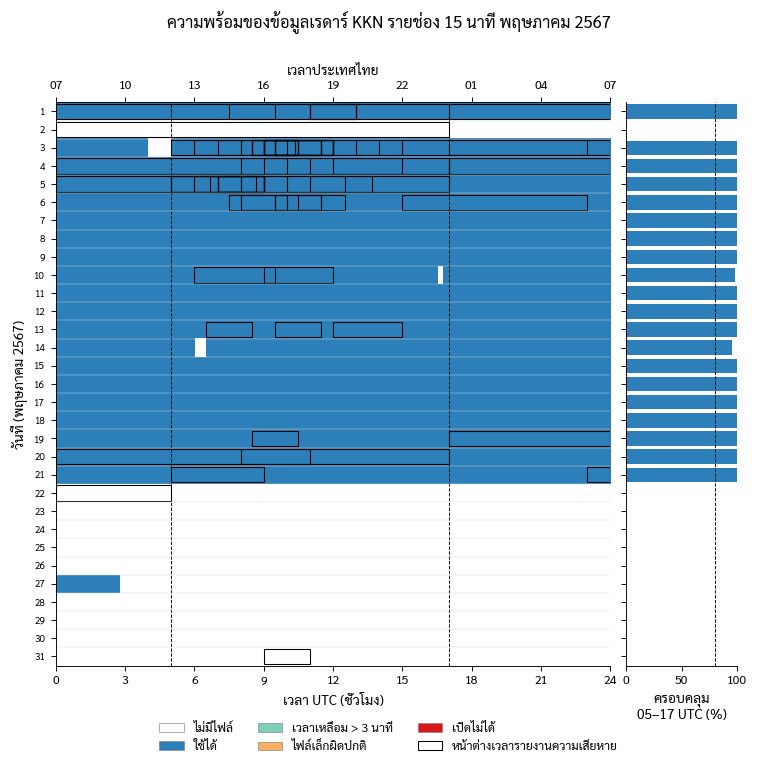

In [9]:
cats = ["missing", "ok", "offset", "small", "corrupt"]
colors = ["#ffffff", "#2c7fb8", "#7fcdbb", "#fdae61", "#d7191c"]
labels = ["ไม่มีไฟล์", "ใช้ได้", "เวลาเหลื่อม > 3 นาที", "ไฟล์เล็กผิดปกติ", "เปิดไม่ได้"]
code = slots["status"].map({c: i for i, c in enumerate(cats)}).fillna(0).astype(int)
days_ = sorted(slots["date"].unique())
grid = code.values.reshape(len(days_), -1)

fig = plt.figure(figsize=(7.2, 6.4))
ax = fig.add_axes([0.08, 0.10, 0.70, 0.80])
axr = fig.add_axes([0.80, 0.10, 0.14, 0.80], sharey=ax)
ax.imshow(grid, aspect="auto", interpolation="nearest", cmap=ListedColormap(colors),
          norm=BoundaryNorm(np.arange(-0.5, len(cats)), len(cats)), extent=(0, 24, len(days_) + 0.5, 0.5))
h0, h1 = s["radar_data"]["core_window_utc"]
ax.axvline(h0, color="k", lw=0.6, ls="--"); ax.axvline(h1, color="k", lw=0.6, ls="--")
for y in np.arange(1.5, len(days_), 1):
    ax.axhline(y, color="0.85", lw=0.3)
# หน้าต่างเวลาของรายงานความเสียหาย (UTC) จากบท 01
rp = repo_path("data", "reports", "reports_may2024_clean.csv")
if rp.exists():
    rep = pd.read_csv(rp, parse_dates=["date", "win_start_utc", "win_end_utc"])
    m0 = pd.Timestamp(year=s["project"]["year_ce"], month=s["project"]["month"], day=1)
    for _, r in rep.iterrows():
        t0_, t1_ = r["win_start_utc"], r["win_end_utc"]
        d = t0_.normalize()
        while d < t1_:                       # หน้าต่างที่ข้ามเที่ยงคืน UTC แบ่งวาดทีละวัน
            a = max((t0_ - d).total_seconds() / 3600, 0)
            b = min((t1_ - d).total_seconds() / 3600, 24)
            if d.month == m0.month and b > a:
                ax.add_patch(plt.Rectangle((a, d.day - 0.42), b - a, 0.84, fill=False, ec="k", lw=0.7))
            d += pd.Timedelta(days=1)
ax.set_xticks(range(0, 25, 3)); ax.set_xlim(0, 24)
ax.set_yticks(range(1, len(days_) + 1)); ax.tick_params(axis="y", labelsize=6.5)
ax.set_xlabel("เวลา UTC (ชั่วโมง)"); ax.set_ylabel("วันที่ (พฤษภาคม 2567)")
top = ax.secondary_xaxis("top"); top.set_xticks(range(0, 25, 3), [f"{(h + 7) % 24:02d}" for h in range(0, 25, 3)])
top.set_xlabel("เวลาประเทศไทย")
axr.barh(daily["date"].dt.day, daily["coverage_core"] * 100, color=np.where(daily["usable"], "#2c7fb8", "#fdae61"), height=0.8)
axr.axvline(s["radar_data"]["usable_min_coverage"] * 100, color="k", lw=0.6, ls="--")
axr.set_xlim(0, 100); axr.set_xlabel("ครอบคลุม\n05–17 UTC (%)"); axr.tick_params(axis="y", labelleft=False)
handles = [plt.Rectangle((0, 0), 1, 1, fc=c, ec="0.5", lw=0.4) for c in colors]
handles.append(plt.Rectangle((0, 0), 1, 1, fill=False, ec="k", lw=0.7))
fig.legend(handles, labels + ["หน้าต่างเวลารายงานความเสียหาย"], loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.04))
fig.suptitle("ความพร้อมของข้อมูลเรดาร์ KKN รายช่อง 15 นาที พฤษภาคม 2567", y=1.03)
M.savefig(fig, "p0_radar_availability", outdir=INV_OUT)
plt.show()

บันทึกรูป → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/inventory/p0_nyquist_sweeps.png / .pdf


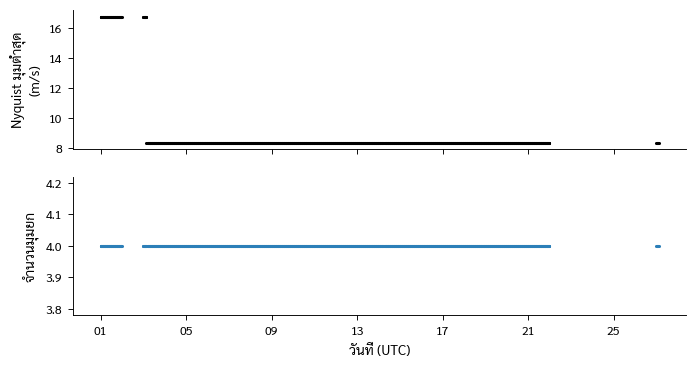

In [10]:
# Nyquist velocity ของมุมยกต่ำสุดตามเวลา — ใช้วางแผน dealiasing ใน P2
if READ_METADATA and files["read_ok"].any():
    ok = files[files["read_ok"] == True].copy()  # noqa: E712
    ok["vny0"] = ok["nyquist"].astype(str).str.split(";").str[0].replace("", np.nan).astype(float)
    ok["n_el"] = ok["nsweeps"]
    fig, axs = plt.subplots(2, 1, figsize=(7.2, 3.6), sharex=True)
    axs[0].plot(ok["slot_utc"], ok["vny0"], ".", ms=2, color="k")
    axs[0].set_ylabel("Nyquist มุมต่ำสุด\n(m/s)")
    axs[1].plot(ok["slot_utc"], ok["n_el"], ".", ms=2, color="#2c7fb8")
    axs[1].set_ylabel("จำนวนมุมยก")
    axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    axs[1].set_xlabel("วันที่ (UTC)")
    M.savefig(fig, "p0_nyquist_sweeps", outdir=INV_OUT)
    plt.show()

## บันทึกผล

ตารางทั้งหมดไม่มีข้อมูลเรดาร์ (มีแค่ชื่อไฟล์ เวลา ขนาด และ metadata) จึงเผยแพร่ใน repo ได้ คอลัมน์ `path` ซึ่งเป็นตำแหน่งใน Drive ส่วนตัวถูกตัดออกก่อนบันทึก

In [11]:
keep = ["slot_utc", "date", "status", "file", "size_mb", "offset_min", "read_ok", "nsweeps", "elevs", "nyquist",
        "gate_m", "max_range_km", "fields", "error"]
inv = slots[[c for c in keep if c in slots.columns]]
for folder in (INV_OUT, INV_REPO):
    inv.to_csv(folder / "radar_inventory.csv", index=False)
    daily.to_csv(folder / "daily_summary.csv", index=False)
    segs.to_csv(folder / "segments.csv", index=False)
    files.drop(columns=["path"]).to_csv(folder / "radar_files.csv", index=False)
    if READ_METADATA:
        strat.to_csv(folder / "scan_strategies.csv")
print("บันทึกใน Drive :", INV_OUT)
print("บันทึกใน repo  :", INV_REPO)

บันทึกใน Drive : /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/inventory
บันทึกใน repo  : /content/Teach_stormTracks_KKN_May2024_HID_doppler/data/inventory


## ขั้นต่อไป

1. ดาวน์โหลดไฟล์ในโฟลเดอร์ `data/inventory/` และ `config/radar_site.json` แล้ว commit เข้า repo (ไฟล์เล็กมาก)
2. รันบท 01 ใหม่ จะได้คอลัมน์ `radar_verifiable` (รายงานใดเรดาร์มีข้อมูลในหน้าต่างเวลา) และระยะทางที่คำนวณจากพิกัดจริง
3. ส่ง `daily_summary.csv`, `scan_strategies.csv` และเวลาที่ใช้ในขั้นที่ 2 กลับมา เพื่อใช้ออกแบบ P1 (CAPPI) และ P2 (dual-pol/Doppler/HID) ให้ตรงกับรูปแบบการสแกนจริง